In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

load data and inspect:

In [6]:
solar = pd.read_csv("solar_system.csv", index_col="Attribute")

print("Shape:", solar.shape)
print("Rows:", solar.shape[0], "| Columns:", solar.shape[1])
print("First five rows:")
print(solar.head())
print("Last five rows:")
print(solar.tail())
print("Column names:", list(solar.columns))
print("Row names:", list(solar.index))

Shape: (20, 10)
Rows: 20 | Columns: 10
First five rows:
                       Mercury  Venus  Earth   Moon   Mars Jupiter  Saturn  \
Attribute                                                                    
Mass (10^24kg)           0.330   4.87   5.97  0.073  0.642    1898     568   
Diameter (km)             4879  12104  12756   3475   6792  142984  120536   
Density (kg/m^3)          5429   5243   5514   3340   3934    1326     687   
Gravity (m/s^2)            3.7    8.9    9.8    1.6    3.7    23.1     9.0   
Escape Velocity (km/s)     4.3   10.4   11.2    2.4    5.0    59.5    35.5   

                       Uranus Neptune   Pluto  
Attribute                                      
Mass (10^24kg)           86.8     102  0.0130  
Diameter (km)           51118   49528    2376  
Density (kg/m^3)         1270    1638    1850  
Gravity (m/s^2)           8.7    11.0     0.7  
Escape Velocity (km/s)   21.3    23.5     1.3  
Last five rows:
                        Mercury Venus Earth M

extract the rows we need:

In [7]:
orbital_period = solar.loc["Orbital Period (days)"].astype(float)
perihelion = solar.loc["Perihelion (10^6 km)"].astype(float)
aphelion = solar.loc["Aphelion (10^6 km)"].astype(float)

print(orbital_period)

Mercury       88.0
Venus        224.7
Earth        365.2
Moon          27.3
Mars         687.0
Jupiter     4331.0
Saturn     10747.0
Uranus     30589.0
Neptune    59800.0
Pluto      90560.0
Name: Orbital Period (days), dtype: float64


definitions:

- Perihelion: the point in orbit where the object is closest to the thing it's orbiting.
- Aphelion: the point in orbit where the object is furthest from the thing it's orbiting.
- Semi-major axis: half of the long diameter of an orbit. It's the average of the distances of the perihelion and aphelion.

In [8]:
semi_major_axis = (perihelion + aphelion) / 2
semi_major_axis.name = "Semi-Major Axis (10^6 km)"

solar = pd.concat([solar, semi_major_axis.to_frame().T])
print("New shape:", solar.shape)
print("Rows:", solar.shape[0], "| Columns:", solar.shape[1])
print(solar.tail())

New shape: (21, 10)
Rows: 21 | Columns: 10
                          Mercury  Venus  Earth    Moon   Mars  Jupiter  \
Surface Pressure (bars)         0     92      1       0   0.01  Unknown   
Number of Moons                 0      0      1       0      2       95   
Ring System?                   No     No     No      No     No      Yes   
Global Magnetic Field?        Yes     No    Yes      No     No      Yes   
Semi-Major Axis (10^6 km)    57.9  108.2  149.6  0.3845  228.0    778.5   

                            Saturn   Uranus  Neptune    Pluto  
Surface Pressure (bars)    Unknown  Unknown  Unknown  0.00001  
Number of Moons                274       28       16        5  
Ring System?                   Yes      Yes      Yes       No  
Global Magnetic Field?         Yes      Yes      Yes  Unknown  
Semi-Major Axis (10^6 km)  1432.05  2867.05   4515.0  5906.35  


Plot the data:

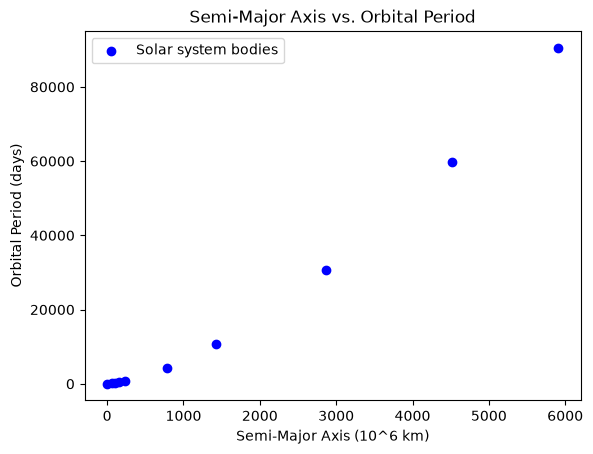

In [9]:
plt.scatter(semi_major_axis, orbital_period, color="blue", label="Solar system bodies")
plt.xlabel("Semi-Major Axis (10^6 km)")
plt.ylabel("Orbital Period (days)")
plt.title("Semi-Major Axis vs. Orbital Period")
plt.legend()
plt.show()

Fit Kepler's Third Law

In [10]:
def keplers_third_law(a, m):
    # T = m * a^1.5
    return m * a ** 1.5

popt, pcov = curve_fit(keplers_third_law, semi_major_axis, orbital_period)
m_fit = popt[0]

print(f"Fit: T = {m_fit:.2f} * a^1.5")

residuals = orbital_period - keplers_third_law(semi_major_axis, m_fit)
chi2 = np.sum(residuals**2)
dof = len(semi_major_axis) - len(popt)
chi2_reduced = chi2 / dof
print(f"Reduced chi-squared: {chi2_reduced:.2f}")

Fit: T = 0.20 * a^1.5
Reduced chi-squared: 41276.71


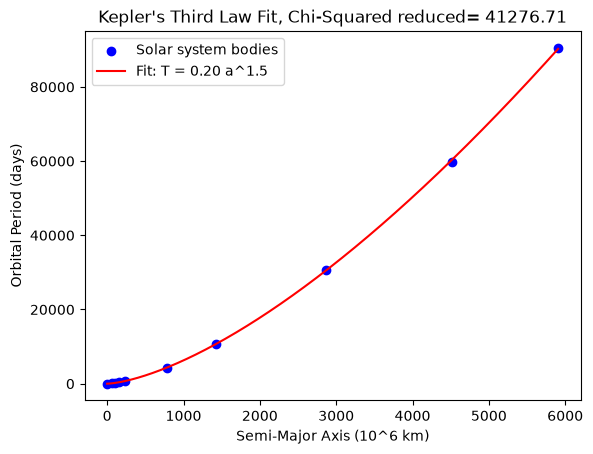

In [11]:
a_smooth = np.linspace(0, semi_major_axis.max(), 500)

plt.scatter(semi_major_axis, orbital_period, color="blue", label="Solar system bodies")
plt.plot(a_smooth, keplers_third_law(a_smooth, m_fit), color="red", label=f"Fit: T = {m_fit:.2f} a^1.5")
plt.xlabel("Semi-Major Axis (10^6 km)")
plt.ylabel("Orbital Period (days)")
plt.title(f"Kepler's Third Law Fit, Chi-Squared reduced= {chi2_reduced:.2f}")
plt.legend()
plt.show()

The curve fit follows the points very well, which is what Kepler's Third Law should predict it to do. The reduced chi-squared is not close to 1 because I didnt divide by measurement problems/uncertainties, so its just the average squared residual in days squared and the outer planets dominate.

save the new dataframe:

In [12]:
solar.to_csv("kepler.csv")